# Perbandingan Model Bahasa untuk Klasifikasi Sentimen Berita Ekonomi

Kandidat: **IndoBERT-base-p1, IndoBERT-base-p2, XLM-R base**.
Tujuan: membuktikan pemilihan model klasifikasi sentimen berdasarkan uji coba pada data berita ekonomi penelitian (Bab 3.8.1 dan Bab 4.4.1).

Output:
- `perbandingan_model_sentimen.csv` — tabel ringkasan
- `perbandingan_model_sentimen_per_seed.csv` — hasil per model per seed
- `confusion_matrix_perbandingan_model.png` dan `.csv` — confusion matrix tiap model

## 1. Instalasi library
Jalankan sekali. Di laptop (venv) cukup pastikan `torch`, `transformers`, `datasets`, `accelerate`, dan `scikit-learn` sudah terpasang.

In [2]:
# Hapus tanda # di bawah jika menjalankan di Colab atau library belum terpasang
# !pip install -q transformers datasets accelerate scikit-learn

## 2. Konfigurasi
Path file anotasi sudah terisi. `KOLOM_TEKS` dan `KOLOM_LABEL` dibiarkan `None` agar dideteksi otomatis; isi manual jika deteksi keliru. Konfigurasi pelatihan **sama dengan fine-tuning di Bab 3** agar perbandingan adil.

In [3]:
FILE_ANOTASI = r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_gabungan_20260722_2343_n1088.csv"
# Di Colab: cukup tulis nama filenya, mis. FILE_ANOTASI = 'anotasi_gabungan_20260722_2343_n1088.csv'
KOLOM_TEKS   = None     # None = deteksi otomatis; atau isi nama kolom, mis. 'Teks'
KOLOM_LABEL  = None     # None = deteksi otomatis; atau isi nama kolom label MANUAL, mis. 'Label_Manual'

KANDIDAT = {
    'IndoBERT-base-p1': 'indobenchmark/indobert-base-p1',
    'IndoBERT-base-p2': 'indobenchmark/indobert-base-p2',
    'XLM-R base'      : 'xlm-roberta-base',
}
SEEDS = [42]          # untuk hasil lebih kuat: [42, 7, 2026] lalu laporkan rata-rata ± std

# Konfigurasi sama dengan Tabel konfigurasi fine-tuning di Bab 3
LR, BATCH, EPOCHS, MAX_LEN = 2e-5, 16, 5, 128
WEIGHT_DECAY, WARMUP       = 0.01, 0.1
TEST_SIZE, SPLIT_SEED      = 0.20, 42           # split dibuat SEKALI, dipakai semua model

## 3. Muat data anotasi dan bagi data latih–validasi
Satu pembagian *stratified* 80:20 dibuat sekali dan dipakai untuk **semua model**. Bobot kelas dihitung dengan rumus $w_c = N / (K \times n_c)$.

**Cek output:** jumlah baris (±1.088), kolom label yang dipakai harus label **manual**, dan data validasi ±218.

In [4]:
import time, numpy as np, pandas as pd, torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             cohen_kappa_score, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)

try:
    df = pd.read_csv(FILE_ANOTASI, encoding='utf-8-sig')
except UnicodeDecodeError:
    df = pd.read_csv(FILE_ANOTASI, encoding='latin-1')
print(f'File dimuat: {len(df)} baris')
print('Kolom tersedia:', df.columns.tolist())

def cari(kandidat, kecuali=()):
    norm = {c.lower().replace(' ', '_'): c for c in df.columns}
    for k in kandidat:
        if k in norm and norm[k] not in kecuali:
            return norm[k]
    return None

if KOLOM_TEKS is None:
    KOLOM_TEKS = cari(['teks', 'text', 'teks_bersih', 'clean_text', 'headline', 'judul', 'title', 'kalimat'])
if KOLOM_LABEL is None:   # utamakan label manual/final, hindari label otomatis leksikon
    KOLOM_LABEL = cari(['label_manual', 'label_final', 'label_valid', 'manual_label', 'label_anotasi',
                        'anotasi', 'label', 'sentimen', 'sentiment', 'label_sentimen', 'kelas'])
if KOLOM_TEKS is None or KOLOM_LABEL is None:
    raise SystemExit(f'\n>> Kolom tidak terdeteksi otomatis. Isi KOLOM_TEKS dan KOLOM_LABEL di Cell 2 '
                     f'dengan salah satu nama kolom di atas.')
print(f'Dipakai -> teks: "{KOLOM_TEKS}" | label: "{KOLOM_LABEL}"')

df = df[[KOLOM_TEKS, KOLOM_LABEL]].dropna()
df[KOLOM_TEKS] = df[KOLOM_TEKS].astype(str).str.strip()
LABELS = ['Negatif', 'Netral', 'Positif']
PETA = {'negatif': 'Negatif', 'negative': 'Negatif', 'neg': 'Negatif', '-1': 'Negatif', '-1.0': 'Negatif',
        'netral': 'Netral', 'neutral': 'Netral', 'neu': 'Netral', '0': 'Netral', '0.0': 'Netral',
        'positif': 'Positif', 'positive': 'Positif', 'pos': 'Positif', '1': 'Positif', '1.0': 'Positif'}
asli = df[KOLOM_LABEL].astype(str).str.strip()
print('Nilai label asli:', asli.value_counts().to_dict())
df[KOLOM_LABEL] = asli.str.lower().map(PETA)
if df[KOLOM_LABEL].isna().any():
    raise SystemExit(f'\n>> Ada nilai label yang tidak dikenali: {sorted(asli[df[KOLOM_LABEL].isna()].unique())[:10]}. '
                     f'Jika label berupa 0/1/2, periksa urutan kelasnya lalu sesuaikan PETA.')
lab2id = {l: i for i, l in enumerate(LABELS)}
df['label'] = df[KOLOM_LABEL].map(lab2id)

tr_df, va_df = train_test_split(df, test_size=TEST_SIZE, stratify=df['label'], random_state=SPLIT_SEED)
print(f'Total {len(df)} | latih {len(tr_df)} | validasi {len(va_df)}')
print(pd.crosstab(df[KOLOM_LABEL], 'n').T)

# bobot kelas: w_c = N / (K × n_c)  — sama dengan Persamaan di Bab 3
w = compute_class_weight('balanced', classes=np.arange(3), y=tr_df['label'])
print('Class weight:', dict(zip(LABELS, w.round(3))))

e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


File dimuat: 1088 baris
Kolom tersedia: ['Kode_Emiten', 'Tanggal', 'Sumber', 'Headline', 'Teks', 'Label_Auto', 'Label_Manual']
Dipakai -> teks: "Teks" | label: "Label_Manual"
Nilai label asli: {'Netral': 624, 'Positif': 269, 'Negatif': 195}
Total 1088 | latih 870 | validasi 218
Label_Manual  Negatif  Netral  Positif
col_0                                 
n                 195     624      269
Class weight: {'Negatif': 1.859, 'Netral': 0.581, 'Positif': 1.349}


## 4. Fungsi pelatihan dan evaluasi
Memakai *weighted cross-entropy*, evaluasi tiap epoch, dan memilih *checkpoint* dengan F1 *macro* terbaik.

In [5]:
CM = {}   # confusion matrix tiap model, untuk disimpan di akhir

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        out = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            out.logits, labels, weight=torch.tensor(w, dtype=torch.float, device=out.logits.device))
        return (loss, out) if return_outputs else loss

def metrik(pred):
    y, p = pred.label_ids, pred.predictions.argmax(-1)
    return {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}

def latih_satu(nama, ckpt, seed):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(ckpt)
    enc = lambda b: tok(b[KOLOM_TEKS], truncation=True, padding='max_length', max_length=MAX_LEN)
    ds_tr = Dataset.from_pandas(tr_df[[KOLOM_TEKS, 'label']].reset_index(drop=True)).map(enc, batched=True)
    ds_va = Dataset.from_pandas(va_df[[KOLOM_TEKS, 'label']].reset_index(drop=True)).map(enc, batched=True)
    model = AutoModelForSequenceClassification.from_pretrained(
        ckpt, num_labels=3, id2label=dict(enumerate(LABELS)), label2id=lab2id)
    args = TrainingArguments(
        output_dir=f'tmp_{nama.replace(" ", "_")}_{seed}', learning_rate=LR,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=32,
        num_train_epochs=EPOCHS, weight_decay=WEIGHT_DECAY, warmup_ratio=WARMUP,
        eval_strategy='epoch', save_strategy='epoch', load_best_model_at_end=True,
        metric_for_best_model='f1_macro', save_total_limit=1, seed=seed,
        report_to='none', fp16=torch.cuda.is_available())
    tr = WeightedTrainer(model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va,
                         compute_metrics=metrik)
    t0 = time.time(); tr.train(); menit = (time.time() - t0) / 60
    y = va_df['label'].values
    p = tr.predict(ds_va).predictions.argmax(-1)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    hasil = {'Model': nama, 'Seed': seed,
             'Parameter (juta)': round(sum(x.numel() for x in model.parameters()) / 1e6, 1),
             'Accuracy': accuracy_score(y, p), 'F1 macro': f1_score(y, p, average='macro'),
             'F1 Negatif': f1[0], 'F1 Netral': f1[1], 'F1 Positif': f1[2],
             'Cohen Kappa': cohen_kappa_score(y, p), 'Waktu latih (menit)': round(menit, 1)}
    cm = confusion_matrix(y, p, labels=[0, 1, 2])
    CM[(nama, seed)] = cm
    print(f'\n{nama} (seed {seed})\n', pd.DataFrame(cm, index=LABELS, columns=LABELS))
    del model, tr; torch.cuda.empty_cache()
    return hasil

## 5. Latih semua kandidat
Di CPU ±30–60 menit per model; di Colab GPU ±5–15 menit per model.

In [6]:
rows = [latih_satu(n, c, s) for n, c in KANDIDAT.items() for s in SEEDS]
hasil = pd.DataFrame(rows)

Map: 100%|██████████| 218/218 [00:00<00:00, 8582.86 examples/s]
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 24017.80it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.782979,0.651376,0.627180
2,No log,0.524657,0.784404,0.772668
3,No log,0.461638,0.844037,0.826064
4,No log,0.547788,0.830275,0.813238
5,No log,0.714573,0.825688,0.803631


Writing model shards: 100%|██████████| 1/1 [00:10<00:00, 10.61s/it]
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:09<00:00,  9.93s/it]
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.15s/it]
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned


IndoBERT-base-p1 (seed 42)
          Negatif  Netral  Positif
Negatif       33       5        1
Netral        10     106        9
Positif        3       6       45


Map: 100%|██████████| 218/218 [00:00<00:00, 8589.80 examples/s]
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 28142.10it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.764987,0.665138,0.639825
2,No log,0.519621,0.770642,0.761070
3,No log,0.427489,0.844037,0.828466
4,No log,0.593017,0.821101,0.800936
5,No log,0.721302,0.825688,0.803631


... (2 outputs left out)

e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Ryzen\.cache\huggingface\hub\models--xlm-roberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8366.02it/s]
[tr

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,1.018337,0.532110,0.476088
2,No log,0.981197,0.674312,0.578012
3,No log,0.721807,0.752294,0.713356
4,No log,0.676372,0.715596,0.700003
5,No log,0.647482,0.752294,0.736069


Writing model shards: 100%|██████████| 1/1 [00:06<00:00,  6.12s/it]
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:06<00:00,  6.17s/it]
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:06<00:00,  6.31s/it]
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\venv_tf_new\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned


XLM-R base (seed 42)
          Negatif  Netral  Positif
Negatif       34       2        3
Netral        19      88       18
Positif        6       6       42


## 6. Ringkasan hasil (untuk Tabel Bab 4.4.1)

In [7]:
num = ['Accuracy', 'F1 macro', 'F1 Negatif', 'F1 Netral', 'F1 Positif', 'Cohen Kappa', 'Waktu latih (menit)']
ring = hasil.groupby('Model', sort=False).agg({'Parameter (juta)': 'first', **{k: 'mean' for k in num}})
if len(SEEDS) > 1:
    ring['F1 macro (std)'] = hasil.groupby('Model', sort=False)['F1 macro'].std()
ring = ring.sort_values('F1 macro', ascending=False).round(4)
print('\n=== PERBANDINGAN MODEL (data validasi berita ekonomi) ===')
print(ring.to_string())
ring.to_csv('perbandingan_model_sentimen.csv')
hasil.to_csv('perbandingan_model_sentimen_per_seed.csv', index=False)

terbaik = ring.index[0]
selisih = ring['F1 macro'].iloc[0] - ring.loc['IndoBERT-base-p2', 'F1 macro']
print(f'\nF1 macro tertinggi: {terbaik}. Selisih terhadap IndoBERT-base-p2: {selisih * 100:.2f} poin.')
print('Catatan: jika selisih kecil (< ±1 poin), pemilihan p2 dapat dipertahankan dengan alasan efisiensi.')


=== PERBANDINGAN MODEL (data validasi berita ekonomi) ===
                  Parameter (juta)  Accuracy  F1 macro  F1 Negatif  F1 Netral  F1 Positif  Cohen Kappa  Waktu latih (menit)
Model                                                                                                                      
IndoBERT-base-p2             124.4    0.8440    0.8285      0.7640     0.8718      0.8496       0.7423                 31.0
IndoBERT-base-p1             124.4    0.8440    0.8261      0.7765     0.8760      0.8257       0.7366                 32.6
XLM-R base                   278.0    0.7523    0.7361      0.6939     0.7964      0.7179       0.6052                 32.8

F1 macro tertinggi: IndoBERT-base-p2. Selisih terhadap IndoBERT-base-p2: 0.00 poin.
Catatan: jika selisih kecil (< ±1 poin), pemilihan p2 dapat dipertahankan dengan alasan efisiensi.


## 7. Simpan confusion matrix tiap model
Untuk lampiran dan Gambar di Bab 4.4.1.

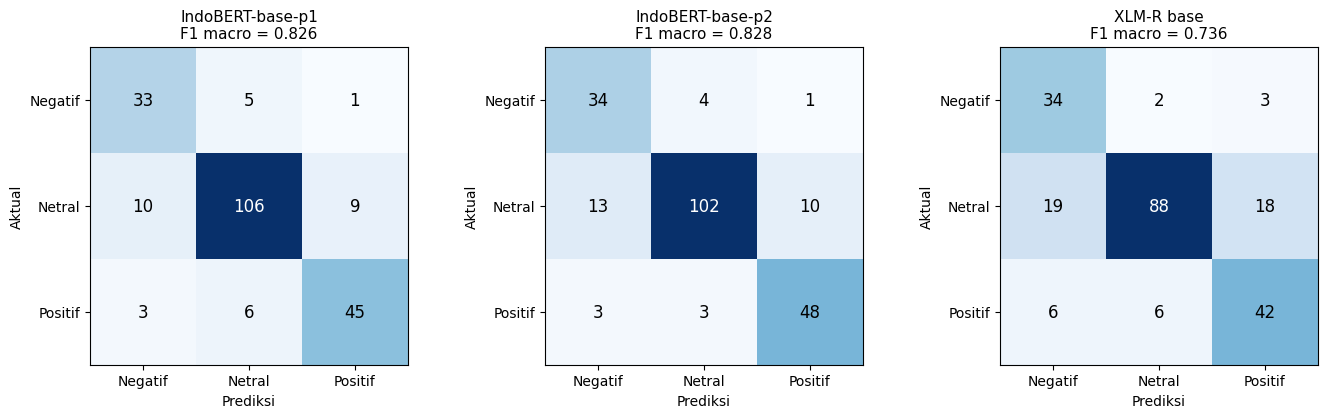

Tersimpan: confusion_matrix_perbandingan_model.png dan .csv


In [8]:
import matplotlib.pyplot as plt
seed0 = SEEDS[0]
fig, axes = plt.subplots(1, len(KANDIDAT), figsize=(4.6 * len(KANDIDAT), 4.2))
baris_csv = []
for ax, nama in zip(np.atleast_1d(axes), KANDIDAT):
    cm = CM[(nama, seed0)]
    ax.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=12,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    f1m = hasil.loc[(hasil['Model'] == nama) & (hasil['Seed'] == seed0), 'F1 macro'].iloc[0]
    ax.set_title(f'{nama}\nF1 macro = {f1m:.3f}', fontsize=11)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
    for i, a in enumerate(LABELS):
        for j, b in enumerate(LABELS):
            baris_csv.append({'Model': nama, 'Seed': seed0, 'Aktual': a, 'Prediksi': b, 'Jumlah': int(cm[i, j])})
plt.tight_layout()
plt.savefig('confusion_matrix_perbandingan_model.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
pd.DataFrame(baris_csv).to_csv('confusion_matrix_perbandingan_model.csv', index=False)
print('Tersimpan: confusion_matrix_perbandingan_model.png dan .csv')